# 03 · Modeling early-onset CRC

**Question:** can state-level structural and modifiable factors predict early-onset (ages 20–49) CRC incidence, and does meat availability add predictive value?

**Outcome:** state-year crude CRC rate among adults aged 20–49.

**Features:** year, state baseline early-onset rate, red meat and poultry availability, adult smoking, adult obesity, uninsured rate, log population, Census region.

**Validation:**
- 5-fold **GroupKFold by state** — can the model generalize to states it has never seen?
- **Temporal holdout** — train through 2016, test 2017–2019 and 2020 separately. 2020 is reported separately because the pandemic disrupted cancer diagnosis.

**Models:** Ridge regression (linear baseline), random forest, histogram gradient boosting (HGB).

In [1]:
import os, sys, tempfile
from pathlib import Path


def _find_project_root(start=None):
    """Walk up from the current directory until we find the repo root."""
    here = Path(start or Path.cwd()).resolve()
    for candidate in (here, *here.parents):
        if (candidate / "src" / "data_prep.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find the project root. Open this notebook from inside the "
        "repository (the folder that contains src/, notebooks/, and outputs/)."
    )


ROOT = _find_project_root()
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mpl"))
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
print(f"Project root: {ROOT.name}")

Project root: DS-5003-group-4-Project


In [2]:
from IPython.display import Image, display
from src import data_prep as dp
from src.model import evaluate, NUMERIC, CATEGORICAL, TARGET
from src.make_figures import fig4_model

metrics, preds, importance, importance_full, df = evaluate()
print(f"Modeling rows: {len(df):,}; states: {df.state_abbr.nunique()}")

Modeling rows: 1,112; states: 51


## 1. Model comparison

GroupKFold R² is similar for all three models (≈0.52–0.54), but the temporal holdout separates them: HGB and random forest hold up, Ridge does not. HGB is selected because it has the best combination of cross-state and future-year performance and handles non-linearities without hand-specified interactions.

In [3]:
metrics.pivot(index="model", columns="validation", values=["r2", "mae"]).round(3)

r2                                                                           mae  \
validation                  5-fold GroupKFold (by state) Temporal holdout 2017-2019 Temporal holdout 2020 5-fold GroupKFold (by state)   
model                                                                                                                                    
Histogram gradient boosting                        0.530                      0.448                 0.245                        1.028   
Random forest                                      0.520                      0.447                 0.094                        1.060   
Ridge regression                                   0.537                      0.297                -0.098                        1.032   

                                                                              
validation                  Temporal holdout 2017-2019 Temporal holdout 2020  
model                                                                         
Histogram gradient boosting                      1.053                 1.149  
Random forest                                    1.052                 1.236  
Ridge regression                                 1.160                 1.349

In [4]:
metrics

,model,validation,r2,mae,n
0,Ridge regression,5-fold GroupKFold (by state),0.537,1.032,1112
1,Ridge regression,Temporal holdout 2017-2019,0.297,1.160,153
2,Ridge regression,Temporal holdout 2020,-0.098,1.349,51
3,Random forest,5-fold GroupKFold (by state),0.520,1.060,1112
4,Random forest,Temporal holdout 2017-2019,0.447,1.052,153
5,Random forest,Temporal holdout 2020,0.094,1.236,51
6,Histogram gradient boosting,5-fold GroupKFold (by state),0.530,1.028,1112
7,Histogram gradient boosting,Temporal holdout 2017-2019,0.448,1.053,153
8,Histogram gradient boosting,Temporal holdout 2020,0.245,1.149,51


**Reading the metrics.** A GroupKFold R² of 0.53 means the model explains about half of the variation in early-onset rates across states it has not seen. The temporal R² is lower (0.45 for 2017–2019, 0.25 for 2020) because the model must extrapolate a rising trend and because 2020 was an anomalous diagnostic year. The MAE of about 1.0–1.1 cases per 100,000 is small relative to the 5.7–20.6 range across states.

## 2. What drives the predictions?

Permutation importance is computed on the final HGB fit to all state-years. The state's baseline burden, the secular year trend, and adult obesity dominate. Meat availability — the exposure of interest — contributes less than 1% of predictive power, and its permutation importance is statistically indistinguishable from zero.

In [5]:
importance_full.round(3)

,feature,importance_mean,importance_std
0,crc_early_rate_baseline,0.305,0.015
1,year,0.272,0.013
2,obesity_pct,0.165,0.008
3,log_population,0.079,0.004
4,smoking_pct,0.078,0.007
5,region,0.058,0.003
6,uninsured_pct,0.040,0.004
7,poultry_lb_pc,0.015,0.002
8,red_meat_lb_pc,0.008,0.001


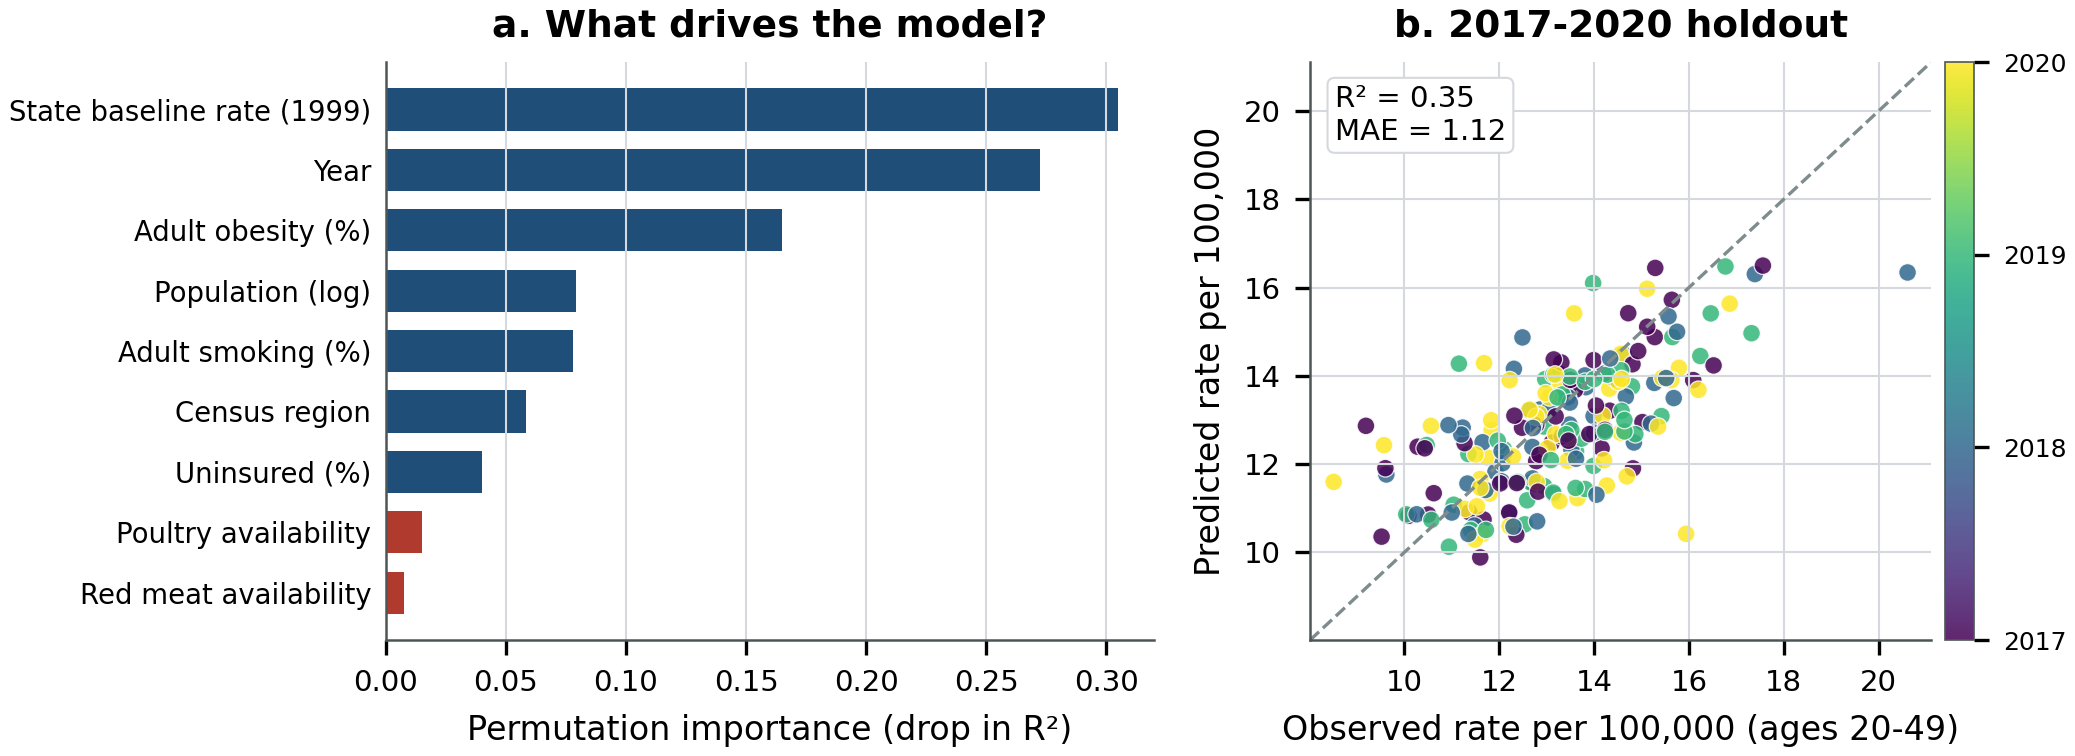

In [6]:
fig = fig4_model(importance_full, preds)
display(Image(filename=fig, width=950))

**Figure 4.** (a) Permutation importance for the final HGB model (drop in R² when a feature is shuffled). Meat variables are shown in red. (b) Observed vs. predicted early-onset CRC rates in the 2017–2020 temporal holdout; the dashed line is perfect prediction.

## 3. Incremental value of meat availability

A nested feature-set comparison makes the same point more directly. Adding meat variables to a baseline model containing year, region, and the state's baseline rate does not improve GroupKFold or temporal R². Adding behavioral covariates (smoking, obesity, insurance) improves cross-state fit but not future-year fit, which is a useful warning against overfitting state-level context.

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import r2_score, mean_absolute_error

reg = pd.get_dummies(df.region, prefix="reg", drop_first=True, dtype=float)
sets = {
    "Baseline: year + region + baseline rate": ["year", "crc_early_rate_baseline"],
    "+ meat availability": ["year", "crc_early_rate_baseline", "red_meat_lb_pc", "poultry_lb_pc"],
    "+ behaviors": ["year", "crc_early_rate_baseline", "red_meat_lb_pc", "poultry_lb_pc", "smoking_pct", "obesity_pct", "uninsured_pct"],
    "+ population": ["year", "crc_early_rate_baseline", "red_meat_lb_pc", "poultry_lb_pc", "smoking_pct", "obesity_pct", "uninsured_pct", "log_population"],
}
rows = []
for name, feats in sets.items():
    X = pd.concat([df[feats], reg], axis=1).fillna(df[feats].median(numeric_only=True))
    y = df[TARGET]
    model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=3, min_samples_leaf=20, random_state=42)
    pred = cross_val_predict(model, X, y, groups=df.state_abbr, cv=GroupKFold(5))
    tr, te = df.year <= 2016, df.year.between(2017, 2019)
    model.fit(X[tr], y[tr])
    rows.append({"feature_set": name, "group_r2": r2_score(y, pred), "group_mae": mean_absolute_error(y, pred),
                 "time_r2": r2_score(y[te], model.predict(X[te])), "time_mae": mean_absolute_error(y[te], model.predict(X[te]))})
pd.DataFrame(rows).round(3)

,feature_set,group_r2,group_mae,time_r2,time_mae
0,Baseline: year + region + baseline rate,0.408,1.210,0.441,1.057
1,+ meat availability,0.413,1.201,0.451,1.043
2,+ behaviors,0.513,1.055,0.410,1.084
3,+ population,0.522,1.035,0.458,1.040


## 4. Interpretation and limitations

- **Prediction, not causation.** The model identifies states with elevated early-onset burden; it does not estimate the causal effect of meat. Meat availability is national, so it cannot vary independently of the year in a state-year panel.
- **Baseline burden is the strongest predictor.** States with high early-onset rates in 1999 remained high; the model mostly ranks persistent burden and adjusts for the national trend.
- **Obesity is the most important modifiable factor** in the model, consistent with the literature on early-onset CRC.
- **2020 is an outlier.** The pandemic reduced diagnoses; the model's 2020 error is larger and should not be used to judge long-run performance.
- **Missing hospital data.** The SID covers 36 states and is unbalanced; adding hospital density did not improve the model (results available in `outputs/cleaned/`), so it is not in the final specification.
